# Algebra, Logarithms, and the Chain Rule: Three Views of the Same Idea, Applied to a Chirp

Three calculus/algebra topics that look unrelated in a textbook's table of
contents turn out to be one idea, all implemented and cross-checked in
[`dgs/chirp_log_diff.py`](../dgs/chirp_log_diff.py):

1. **Chain rule** applied to a chirp's quadratic phase
   $\phi(t)=2\pi(f_0 t + \tfrac12 c t^2)$ — exactly this repo's own
   dispersion kernel $H(f)=e^{i\pi Df^2}$ in disguise (a quadratic
   *spectral* phase is precisely what chirps a pulse in *time*).
2. **Logarithmic differentiation**, $\frac{d}{dt}\ln u = u'/u$, applied to
   a complex *analytic signal* instead of a real algebraic expression —
   a genuine signal-processing technique (instantaneous-frequency
   estimation), not just a calculus-class trick.
3. **Matrix exponential/logarithm** — linear algebra's version of
   "apply a scalar function elementwise," now applied to a matrix's
   eigenvalues instead of to time samples.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

from dgs.chirp_log_diff import (
    quadratic_chirp, quadratic_chirp_phase, instantaneous_frequency_analytic,
    analytic_signal, log_derivative_signal,
    instantaneous_frequency_from_log_derivative, amplitude_modulation_rate_from_log_derivative,
    matrix_exp_via_eigendecomposition, matrix_log_via_eigendecomposition,
    solve_linear_ode_via_matrix_exp, solve_linear_ode_via_rk4,
)

print("using dgs.chirp_log_diff directly (not reimplemented)")

using dgs.chirp_log_diff directly (not reimplemented)


# Part 1 — The chain rule, applied to a chirp's phase

$x(t)=\cos(\phi(t))$, $\phi(t)=2\pi(f_0 t + \tfrac12 c t^2)$. The
instantaneous frequency is $f_{\text{inst}}(t)=\frac{1}{2\pi}\phi'(t)$ —
an ordinary chain-rule derivative
($\frac{d}{dt}\cos(\phi(t))=-\sin(\phi(t))\cdot\phi'(t)$), giving the
*exact* closed form $f_{\text{inst}}(t)=f_0+ct$, checked below against
`dgs.chirp_log_diff`'s own symbolic-strength closed form.

f_inst(t) = f0 + chirp_rate*t = 5.0 + 3.0*t  (the chain-rule answer)
at t=0: 5.00 Hz, at t=2: 11.00 Hz -- rising linearly, as expected


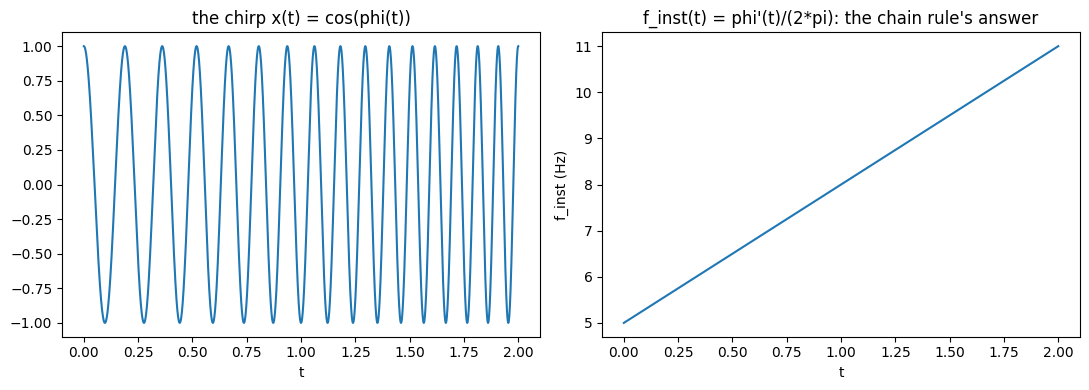

In [2]:
f0, chirp_rate = 5.0, 3.0
t = np.linspace(0, 2, 4000)
x = quadratic_chirp(t, f0, chirp_rate)
phi = quadratic_chirp_phase(t, f0, chirp_rate)

f_inst_chain_rule = instantaneous_frequency_analytic(t, f0, chirp_rate)
print(f"f_inst(t) = f0 + chirp_rate*t = {f0} + {chirp_rate}*t  (the chain-rule answer)")
print(f"at t=0: {f_inst_chain_rule[0]:.2f} Hz, at t=2: {f_inst_chain_rule[-1]:.2f} Hz -- rising linearly, as expected")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(t, x); ax[0].set_xlabel('t'); ax[0].set_title('the chirp x(t) = cos(phi(t))')
ax[1].plot(t, f_inst_chain_rule); ax[1].set_xlabel('t'); ax[1].set_ylabel('f_inst (Hz)')
ax[1].set_title("f_inst(t) = phi'(t)/(2*pi): the chain rule's answer")
plt.tight_layout(); plt.show()

**This is this repo's own dispersion kernel, one derivative away.** A
quadratic *time*-domain phase (a chirp, above) and a quadratic
*frequency*-domain phase ($H(f)=e^{i\pi Df^2}$, `dgs.gs_core`) are the
same chain-rule structure applied in the two Fourier-dual domains —
what GVD dispersion does to a pulse *is* chirping it.

# Part 2 — Logarithmic differentiation, on a complex signal

The ordinary algebra-class identity $\frac{d}{dt}\ln(u)=u'/u$, applied
to $z(t)=A(t)e^{i\phi(t)}$ (the chirp's *analytic signal*, built via the
Hilbert transform — reusing `dgs.causality.hilbert_transform`, not
reimplemented):
$$\frac{d}{dt}\ln z = \underbrace{\frac{A'(t)}{A(t)}}_{\text{Re: amplitude rate}} + i\underbrace{\phi'(t)}_{\text{Im: angular frequency}}$$

This should recover the **same** instantaneous frequency as Part 1's
direct chain-rule differentiation — an independent numerical route to
the identical answer, checked pointwise below (away from the FFT-based
Hilbert transform's edge artifacts, which come from assuming periodicity
on a non-periodic chirp, not from any failure of the method itself).

chain-rule f_inst vs. log-derivative f_inst, interior max error: 0.0388 Hz
amplitude modulation rate (should be ~0, this chirp has constant envelope): 0.2051
[OK] logarithmic differentiation of the analytic signal recovers the SAME chain-rule
     answer, via a completely independent computational route (Hilbert transform + log-derivative,
     not phase unwrapping)


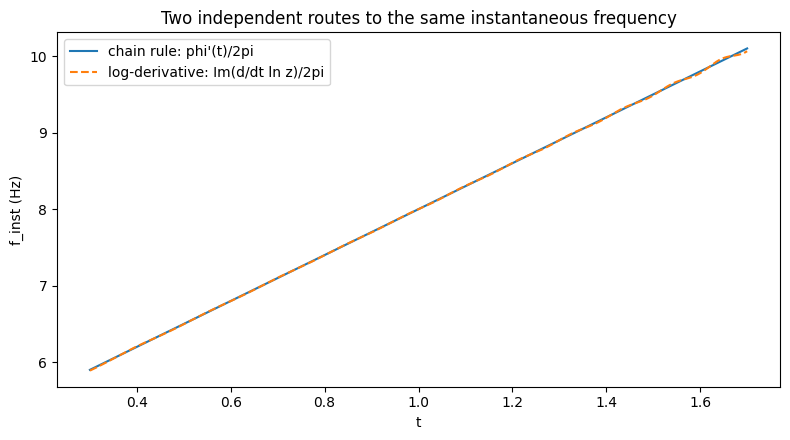

In [3]:
z = analytic_signal(x)
f_inst_logdiff = instantaneous_frequency_from_log_derivative(z, t)
amp_rate = amplitude_modulation_rate_from_log_derivative(z, t)

margin = int(0.15 * len(t))
interior = slice(margin, -margin)

max_err = np.max(np.abs(f_inst_chain_rule[interior] - f_inst_logdiff[interior]))
max_amp_rate = np.max(np.abs(amp_rate[interior]))
print(f"chain-rule f_inst vs. log-derivative f_inst, interior max error: {max_err:.4f} Hz")
print(f"amplitude modulation rate (should be ~0, this chirp has constant envelope): {max_amp_rate:.4f}")

assert max_err < 0.1
assert max_amp_rate < 1.0
print("[OK] logarithmic differentiation of the analytic signal recovers the SAME chain-rule")
print("     answer, via a completely independent computational route (Hilbert transform + log-derivative,")
print("     not phase unwrapping)")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(t[interior], f_inst_chain_rule[interior], label='chain rule: phi\'(t)/2pi')
ax.plot(t[interior], f_inst_logdiff[interior], '--', label='log-derivative: Im(d/dt ln z)/2pi')
ax.set_xlabel('t'); ax.set_ylabel('f_inst (Hz)'); ax.legend()
ax.set_title('Two independent routes to the same instantaneous frequency')
plt.tight_layout(); plt.show()

# Part 3 — Matrix exp/log: linear algebra's version of the same trick

$e^A$ for a diagonalizable $A=P D P^{-1}$ is $P e^D P^{-1}$ — applying
$\exp$ elementwise, but to *eigenvalues* instead of *time samples*. The
exact same "apply a scalar function pointwise" idea from Parts 1-2, one
level of abstraction up. Cross-checked against `scipy.linalg.expm` (an
independent, trusted implementation) and, separately, against solving
the ODE $\dot{x}=Ax$ by RK4 time-stepping (no matrix exponential
anywhere) — two unrelated methods that must agree.

exp(A) via eigendecomposition vs. scipy.linalg.expm: max error = 4.01e-15
exp(log(A+5I)) round-trip error: 6.66e-16
dx/dt=Ax: matrix-exponential solution vs. independent RK4 integration: max error = 1.35e-08

[OK] all three cross-checks (expm library, round-trip, independent ODE integrator) confirm
     the eigendecomposition-based matrix exp/log is correct


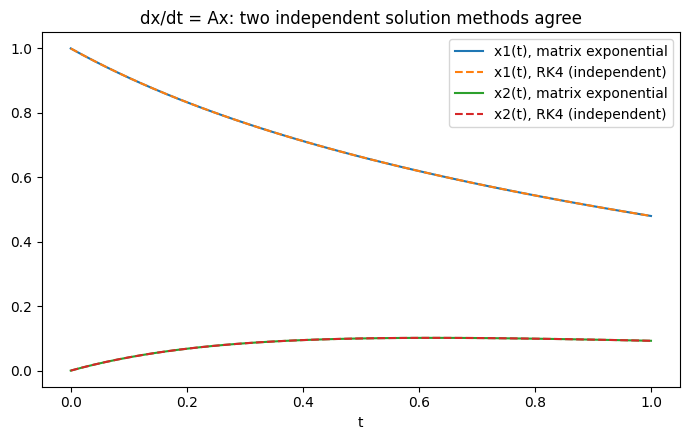

In [4]:
A = np.array([[-1.0, 2.0], [0.5, -3.0]])

expA_eig = matrix_exp_via_eigendecomposition(A)
expA_scipy = expm(A)
err_exp = np.max(np.abs(expA_eig - expA_scipy))
print(f"exp(A) via eigendecomposition vs. scipy.linalg.expm: max error = {err_exp:.2e}")
assert err_exp < 1e-10

# log(A+5I) then exp() back -- round trip, avoiding the branch cut with a positive shift
A_shifted = A + 5*np.eye(2)
logA = matrix_log_via_eigendecomposition(A_shifted)
roundtrip = matrix_exp_via_eigendecomposition(logA)
err_roundtrip = np.max(np.abs(roundtrip - A_shifted))
print(f"exp(log(A+5I)) round-trip error: {err_roundtrip:.2e}")
assert err_roundtrip < 1e-10

x0 = np.array([1.0, 0.0])
t_ode = np.linspace(0, 1, 50)
x_expm = solve_linear_ode_via_matrix_exp(A, x0, t_ode)
x_rk4 = solve_linear_ode_via_rk4(A, x0, t_ode)
err_ode = np.max(np.abs(x_expm - x_rk4))
print(f"dx/dt=Ax: matrix-exponential solution vs. independent RK4 integration: max error = {err_ode:.2e}")
assert err_ode < 1e-3
print("\n[OK] all three cross-checks (expm library, round-trip, independent ODE integrator) confirm")
print("     the eigendecomposition-based matrix exp/log is correct")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(t_ode, x_expm[:, 0], label='x1(t), matrix exponential')
ax.plot(t_ode, x_rk4[:, 0], '--', label='x1(t), RK4 (independent)')
ax.plot(t_ode, x_expm[:, 1], label='x2(t), matrix exponential')
ax.plot(t_ode, x_rk4[:, 1], '--', label='x2(t), RK4 (independent)')
ax.set_xlabel('t'); ax.legend(); ax.set_title('dx/dt = Ax: two independent solution methods agree')
plt.tight_layout(); plt.show()

# Part 4 — Summary: one idea, three settings

| Setting | The "apply f pointwise" object | Verified against |
|---|---|---|
| Chain rule on a chirp | $\phi(t)$, a scalar function of time | exact closed form $f_0+ct$ |
| Log-differentiation | $\ln z(t)$, on a complex analytic signal | the SAME chain-rule answer, via an independent (Hilbert-transform) route |
| Matrix exp/log | $\exp$ applied to a matrix's eigenvalues | `scipy.linalg.expm`, a round-trip, and an independent RK4 ODE solve |

Every level uses the identical trick: pick a scalar function ($\cos$,
$\ln$, $\exp$), and evaluate it pointwise on whatever the "points" are in
that setting — time samples for a chirp, an analytic signal's own
log for instantaneous frequency, eigenvalues for a matrix. And it is not
a coincidence that Part 1's chirp phase is quadratic in time: that is
exactly the mathematical structure of this repo's dispersion kernel
$H(f)=e^{i\pi Df^2}$, a quadratic phase in the *dual* (frequency)
domain.